# S10 — Leonardo | Pronóstico del número de aeronaves observadas en Perú
**Proyecto Sello, Unidad II — CRISP-DM.** Fuente: ADSB.lol histórico, cinco jornadas reales (26–30 de diciembre de 2024).

**Pregunta:** ¿Cuántas aeronaves ICAO24 diferentes se observarán en la región delimitada de Perú durante los próximos 5 minutos?

**Separación metodológica:** el Parquet de noviembre de 2026 es una *reproducción*; aquí entrenamos y evaluamos usando los tiempos originales de 2024. Luego se puede hacer inferencia operativa con OpenSky en Kafka. No corresponde a todo el tráfico aéreo peruano, sino a los vuelos observados por el proveedor.

## 1. Entendimiento del negocio y carga de datos
Decisión: disponer de un pronóstico de corto plazo de aeronaves observadas para dimensionar el monitoreo. Evaluaremos cronológicamente: **26–28 entrenamiento, 29 validación, 30 prueba final**.

In [1]:
APP_NAME='S10-Leonardo-Trafico-Peru'
PREGUNTA='¿Cuantas aeronaves distintas se observaran en los proximos 5 minutos en Peru?'
UNIDAD='aeronaves'
ID_MODELO='leonardo_trafico'

from pathlib import Path
import json, math
from pyspark.sql import SparkSession, functions as F
from pyspark.sql.window import Window
from pyspark.sql.types import StructType, StructField, StringType, IntegerType, DoubleType, BooleanType
from pyspark.ml import Pipeline, PipelineModel
from pyspark.ml.feature import VectorAssembler
from pyspark.ml.regression import LinearRegression, RandomForestRegressor
from pyspark.ml.evaluation import RegressionEvaluator

# Si Spark ya estaba iniciado sin conector Kafka, reiniciar el kernel para streaming.
PAQUETE = 'org.apache.spark:spark-sql-kafka-0-10_2.13:4.2.0'
spark = (SparkSession.builder.appName(APP_NAME).master('local[2]')
    .config('spark.jars.packages', PAQUETE)
    .config('spark.sql.session.timeZone','UTC')
    .config('spark.sql.shuffle.partitions','8')
    .getOrCreate())
spark.sparkContext.setLogLevel('ERROR')
ROOT = Path('/workspace/artifacts/s10')
ROOT.mkdir(parents=True, exist_ok=True)
RUTA = '/workspace/artifacts/s10/peru_historico_unificado'
assert Path(RUTA).exists(), f'Falta el Parquet historico: {RUTA}'
df = spark.read.parquet(RUTA)
print('Spark', spark.version)
print('Registros de origen:', df.count())
print('Fuente: ADSB.lol Peru, 26–30 diciembre de 2024. NO son vuelos de noviembre 2026.')

:: loading settings :: url = jar:file:/usr/local/lib/python3.10/site-packages/pyspark/jars/ivy-2.5.3.jar!/org/apache/ivy/core/settings/ivysettings.xml
Ivy Default Cache set to: /root/.ivy2.5.2/cache
The jars for the packages stored in: /root/.ivy2.5.2/jars
org.apache.spark#spark-sql-kafka-0-10_2.13 added as a dependency
:: resolving dependencies :: org.apache.spark#spark-submit-parent-263ca515-ff3a-47a3-adfd-7f71ffeca597;1.0
	confs: [default]
	found org.apache.spark#spark-sql-kafka-0-10_2.13;4.2.0 in central
	found org.apache.spark#spark-token-provider-kafka-0-10_2.13;4.2.0 in central
	found org.apache.kafka#kafka-clients;3.9.2 in central
	found at.yawk.lz4#lz4-java;1.11.0 in central
	found org.xerial.snappy#snappy-java;1.1.10.8 in central
	found org.slf4j#slf4j-api;2.0.17 in central
	found org.apache.hadoop#hadoop-client-runtime;3.5.0 in central
	found org.apache.hadoop#hadoop-client-api;3.5.0 in central
	found com.google.code.findbugs#jsr305;3.0.0 in central
	found org.scala-lang.mod

Spark 4.2.0


[Stage 1:>                                                          (0 + 2) / 2]

Registros de origen: 184753
Fuente: ADSB.lol Peru, 26–30 diciembre de 2024. NO son vuelos de noviembre 2026.


## 2. Comprensión y calidad de datos
Se conservan aeronaves con ICAO24 y coordenadas válidas. El conteo por ventana se interpreta como aeronaves **observadas** por el dataset; no imputamos cero en períodos sin cobertura.

In [2]:
base=(df.filter(F.col('icao24').rlike('^[0-9a-f]{6}$'))
      .filter(F.col('eventTimestamp').isNotNull())
      .filter(F.col('latitude').between(-18.35,-0.04)&F.col('longitude').between(-81.33,-68.65))
      .filter(F.col('positionStale').isNull() | (F.lower(F.col('positionStale').cast('string'))=='false')))
print('Filas validas:',base.count())
base.groupBy('fecha').agg(F.count('*').alias('observaciones'),F.countDistinct('icao24').alias('ICAO24')).orderBy('fecha').show()

Filas validas: 175637


[Stage 7:>                                                          (0 + 2) / 2]

+----------+-------------+------+
|     fecha|observaciones|ICAO24|
+----------+-------------+------+
|2024-12-26|        34250|   160|
|2024-12-27|        38817|   169|
|2024-12-28|        36220|   169|
|2024-12-29|        36200|   167|
|2024-12-30|        30150|   171|
+----------+-------------+------+



## 3. Preparación: ventanas, etiqueta futura y variables
`label` se obtiene únicamente durante entrenamiento a partir del siguiente intervalo **exactamente 5 minutos después**. Las variables que se entregan al modelo pertenecen solo a la ventana actual o a su hora. No se generan ceros para huecos no observados.

Se usa `approx_count_distinct` para mantener el mismo estimador de conteo que la inferencia Structured Streaming. Se advierte que es aproximado. Las ventanas sin observaciones NO se inventan como cero.

In [3]:
buckets=(base.groupBy(F.window('eventTimestamp','5 minutes').alias('w'))
  .agg(F.approx_count_distinct('icao24').alias('aeronaves'),F.count('*').alias('observaciones'),
       F.avg('velocity').alias('vel_media'),F.avg('baroAltitude').alias('alt_media'))
  .select(F.col('w.start').alias('inicio'),F.col('w.end').alias('fin'),
          'aeronaves','observaciones','vel_media','alt_media')
  .withColumn('fecha',F.to_date('inicio'))
  .withColumn('hora_decimal',F.hour('inicio')+F.minute('inicio')/60.0)
  .withColumn('hora_sin',F.sin(F.col('hora_decimal')*F.lit(2*math.pi/24)))
  .withColumn('hora_cos',F.cos(F.col('hora_decimal')*F.lit(2*math.pi/24)))
  .withColumn('dia_semana',F.dayofweek('inicio').cast('double'))
  .fillna({'vel_media':0.0,'alt_media':0.0}))
orden=Window.orderBy('inicio')
pares=(buckets.withColumn('siguiente_inicio',F.lead('inicio').over(orden))
  .withColumn('label',F.lead('aeronaves').over(orden).cast('double'))
  .filter(F.col('siguiente_inicio')==F.col('fin'))
  .withColumn('persistencia',F.col('aeronaves').cast('double')))
FEATURES=['aeronaves','observaciones','vel_media','alt_media','hora_sin','hora_cos','dia_semana']
COLUMNAS_SALIDA=['inicio','fin','siguiente_inicio','aeronaves']
ORDEN_SALIDA=['inicio']
print('Ventanas:',buckets.count(),'Ejemplos supervisados:',pares.count())
pares.groupBy('fecha').count().orderBy('fecha').show()
pares.select('inicio','aeronaves','siguiente_inicio','label').orderBy('inicio').show(8,False)

Ventanas: 1438 Ejemplos supervisados: 1435


+----------+-----+
|     fecha|count|
+----------+-----+
|2024-12-26|  284|
|2024-12-27|  288|
|2024-12-28|  288|
|2024-12-29|  288|
|2024-12-30|  287|
+----------+-----+



[Stage 31:=============================>                            (1 + 1) / 2]

+-------------------+---------+-------------------+-----+
|inicio             |aeronaves|siguiente_inicio   |label|
+-------------------+---------+-------------------+-----+
|2024-12-26 00:00:00|4        |2024-12-26 00:05:00|2.0  |
|2024-12-26 00:05:00|2        |2024-12-26 00:10:00|1.0  |
|2024-12-26 00:10:00|1        |2024-12-26 00:15:00|2.0  |
|2024-12-26 00:15:00|2        |2024-12-26 00:20:00|4.0  |
|2024-12-26 00:20:00|4        |2024-12-26 00:25:00|4.0  |
|2024-12-26 00:25:00|4        |2024-12-26 00:30:00|2.0  |
|2024-12-26 00:30:00|2        |2024-12-26 00:35:00|2.0  |
|2024-12-26 00:35:00|2        |2024-12-26 00:40:00|3.0  |
+-------------------+---------+-------------------+-----+
only showing top 8 rows


## 4. División temporal estricta
La elección del ganador usa solo validación de 29/12. La prueba de 30/12 queda reservada para el reporte final.

In [4]:
train=pares.filter(F.col('fecha').between('2024-12-26','2024-12-28')).cache()
val=pares.filter(F.col('fecha')=='2024-12-29').cache()
test=pares.filter(F.col('fecha')=='2024-12-30').cache()
print('Train:',train.count(),'Validacion:',val.count(),'Test:',test.count())
assert min(train.count(),val.count(),test.count())>=20,'No hay suficientes ventanas por periodo'

Train: 860 Validacion: 288 Test: 287


## 5. Entrenamiento y comparativa
Comparamos **persistencia**, **regresión lineal** y **Random Forest** con las mismas particiones. Métricas: RMSE, MAE y R²; las métricas del test **no** intervienen en la elección.

Primero se selecciona por validación de 29/12. Después se abre una única vez el test de 30/12 y se reportan los tres modelos sin modificar el ganador.

In [5]:
# Separación estricta: seleccionar SOLO en validación y abrir test al final.
from pyspark.ml.evaluation import RegressionEvaluator
import pandas as pd

def metricas(p, pred='prediction'):
    ev=RegressionEvaluator(labelCol='label',predictionCol=pred)
    return {m:float(ev.setMetricName(m).evaluate(p)) for m in ('rmse','mae','r2')}

candidatos={
 'Regresion lineal': LinearRegression(featuresCol='features',labelCol='label',regParam=0.1,maxIter=100),
 'Random Forest': RandomForestRegressor(featuresCol='features',labelCol='label',numTrees=40,maxDepth=6,seed=42)
}
modelos={}
reportes=[]
valid_persist=val.withColumn('prediction',F.col('persistencia').cast('double'))
metr=metricas(valid_persist)
reportes.append({'modelo':'Persistencia',**{k+'_val':v for k,v in metr.items()}})
for nombre,estimador in candidatos.items():
    pipeline=Pipeline(stages=[VectorAssembler(inputCols=FEATURES,outputCol='features',handleInvalid='error'),estimador])
    modelo=pipeline.fit(train)
    modelos[nombre]=modelo
    m=metricas(modelo.transform(val))
    reportes.append({'modelo':nombre,**{k+'_val':v for k,v in m.items()}})
    print('VALIDACION',nombre,m)

tabla_validacion=pd.DataFrame(reportes).sort_values('rmse_val')
seleccionado=tabla_validacion.iloc[0]['modelo']
print('ELEGIDO EXCLUSIVAMENTE EN VALIDACION:',seleccionado)
display(tabla_validacion.round(4))

# Prueba final: solo ahora se consulta el 30/12/2024.
preds_test={}
for nombre in ['Persistencia','Regresion lineal','Random Forest']:
    p=(test.withColumn('prediction',F.col('persistencia').cast('double')) if nombre=='Persistencia'
       else modelos[nombre].transform(test))
    preds_test[nombre]=p
    m=metricas(p)
    for fila in reportes:
        if fila['modelo']==nombre:
            fila.update({k+'_test':v for k,v in m.items()})

# Resultados finales de todos los candidatos, elegidos por validación solamente.
tabla=pd.DataFrame(reportes).sort_values('rmse_val')
display(tabla.round(4))
resultado_test=(preds_test[seleccionado]
    .select(*COLUMNAS_SALIDA,'label','prediction','persistencia')
    .withColumn('error',F.col('prediction')-F.col('label'))
    .withColumn('error_abs',F.abs(F.col('error')))
    .withColumn('modelo',F.lit(seleccionado)))
print('PRUEBA FINAL DEL GANADOR:',metricas(resultado_test))
assert resultado_test.count()>0


netlib-blas: JNI_OnLoad: dlopen(libblas.so.3) failed: libblas.so.3: cannot open shared object file: No such file or directory
netlib-lapack: JNI_OnLoad: dlopen(liblapack.so.3) failed: liblapack.so.3: cannot open shared object file: No such file or directory


VALIDACION Regresion lineal {'rmse': 1.3022936937782221, 'mae': 1.0287905860013737, 'r2': 0.7482268519121529}
VALIDACION Random Forest {'rmse': 1.3064118922695536, 'mae': 1.0368985934952977, 'r2': 0.7466319870918146}
ELEGIDO EXCLUSIVAMENTE EN VALIDACION: Regresion lineal


,modelo,rmse_val,mae_val,r2_val
1,Regresion lineal,1.3023,1.0288,0.7482
2,Random Forest,1.3064,1.0369,0.7466
0,Persistencia,1.3294,1.0035,0.7376


,modelo,rmse_val,mae_val,r2_val,rmse_test,mae_test,r2_test
1,Regresion lineal,1.3023,1.0288,0.7482,1.3840,1.0863,0.6962
2,Random Forest,1.3064,1.0369,0.7466,1.3414,1.0433,0.7146
0,Persistencia,1.3294,1.0035,0.7376,1.4056,1.0348,0.6866


PRUEBA FINAL DEL GANADOR: {'rmse': 1.383974992439501, 'mae': 1.0863354131952057, 'r2': 0.6961666724628555}


In [6]:
# La celda anterior ya entrena y evalua los candidatos correctamente.
print('Modelo elegido:',seleccionado)

Modelo elegido: Regresion lineal


## 6. Respuesta a la pregunta mediante gráficas
La serie visualiza el conteo observado del **siguiente** intervalo frente a su predicción realizada con información de la ventana actual. Un error pequeño debe interpretarse junto con la referencia de persistencia.

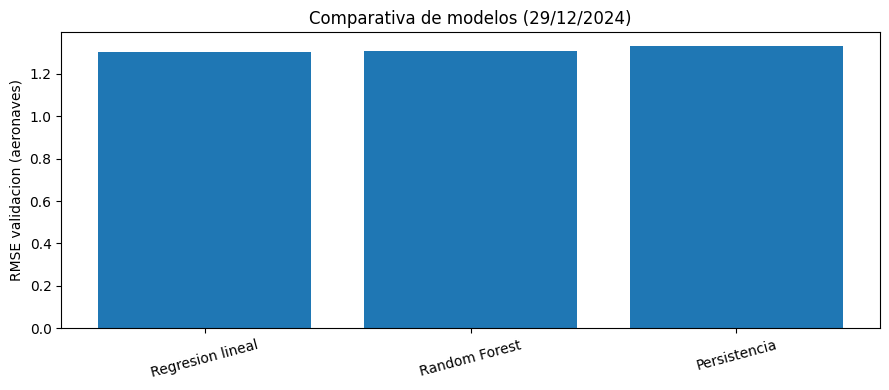

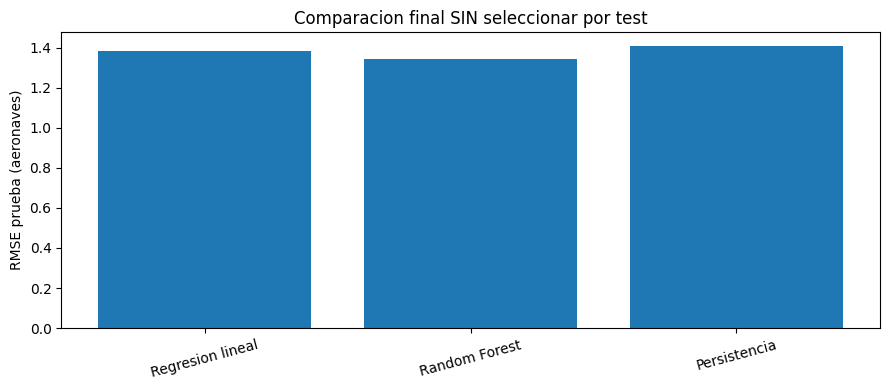

/usr/local/lib/python3.10/site-packages/pyspark/sql/pandas/conversion.py:348: UserWarning: toPandas attempted Arrow optimization because 'spark.sql.execution.arrow.pyspark.enabled' is set to true; however, failed by the reason below:
  [PACKAGE_NOT_INSTALLED] PyArrow >= 18.0.0 must be installed; however, it was not found.
Attempting non-optimization as 'spark.sql.execution.arrow.pyspark.fallback.enabled' is set to true.
  warn(msg)


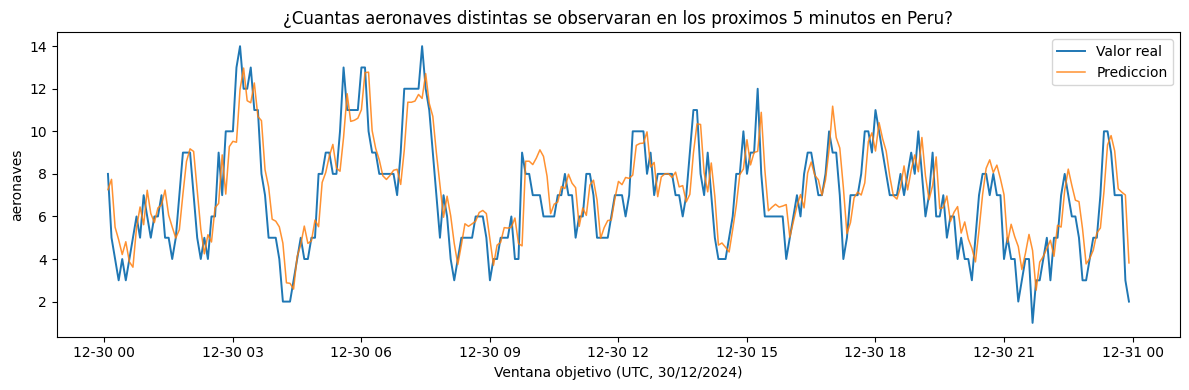

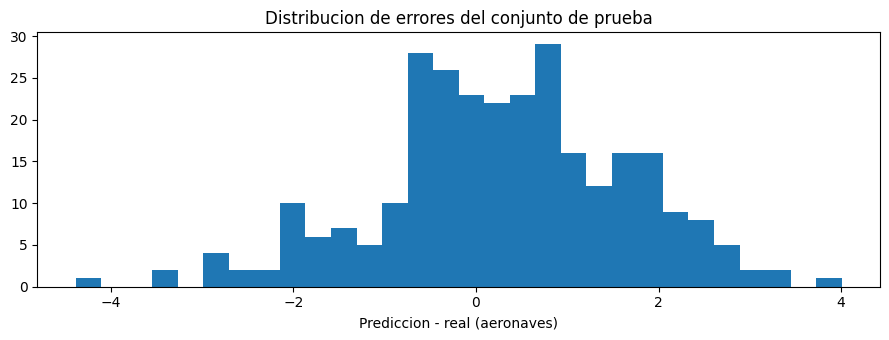

RESPUESTA A LA PREGUNTA: ¿Cuantas aeronaves distintas se observaran en los proximos 5 minutos en Peru?
Modelo seleccionado: Regresion lineal
Metricas en prueba (30/12): {'rmse': 1.383974992439501, 'mae': 1.0863354131952057, 'r2': 0.6961666724628555}


In [7]:
import matplotlib.pyplot as plt
import pandas as pd

fig,ax=plt.subplots(figsize=(9,4))
ax.bar(tabla['modelo'],tabla['rmse_val'])
ax.set_ylabel('RMSE validacion ('+UNIDAD+')'); ax.set_title('Comparativa de modelos (29/12/2024)')
ax.tick_params(axis='x',rotation=15)
plt.tight_layout();plt.show()

fig,ax=plt.subplots(figsize=(9,4))
ax.bar(tabla['modelo'],tabla['rmse_test'])
ax.set_ylabel('RMSE prueba ('+UNIDAD+')');ax.set_title('Comparacion final SIN seleccionar por test')
ax.tick_params(axis='x',rotation=15)
plt.tight_layout();plt.show()

vista=resultado_test.orderBy(*ORDEN_SALIDA).limit(1600).toPandas()
fig,ax=plt.subplots(figsize=(12,4))
if 'inicio' in vista.columns:
    eje=pd.to_datetime(vista['siguiente_inicio'] if 'siguiente_inicio' in vista.columns else vista['fin'])
    ax.set_xlabel('Ventana objetivo (UTC, 30/12/2024)')
else:
    eje=range(len(vista))
    ax.set_xlabel('Observaciones de prueba en orden cronologico (muestra)')
ax.plot(eje,vista['label'],label='Valor real',lw=1.4)
ax.plot(eje,vista['prediction'],label='Prediccion',lw=1.1,alpha=.85)
ax.set_ylabel(UNIDAD);ax.set_title(PREGUNTA)
ax.legend();plt.tight_layout();plt.show()

fig,ax=plt.subplots(figsize=(9,3.5))
ax.hist(vista['error'].dropna(),bins=30)
ax.set_title('Distribucion de errores del conjunto de prueba')
ax.set_xlabel('Prediccion - real ('+UNIDAD+')')
plt.tight_layout();plt.show()

print('RESPUESTA A LA PREGUNTA:',PREGUNTA)
print('Modelo seleccionado:',seleccionado)
print('Metricas en prueba (30/12):',metricas(resultado_test))


## 7. Persistencia y evidencias para S11
Guardamos el mejor modelo MLlib y exportamos la tabla de comparación, resultados de la prueba y configuración con trazabilidad.

In [8]:
# Guardar los modelos ML realmente entrenados y el candidato elegido.
MODELO_RUTA=str(ROOT/'models'/ID_MODELO)
Path(MODELO_RUTA).parent.mkdir(parents=True,exist_ok=True)
ml_mejor=tabla_validacion[tabla_validacion.modelo!='Persistencia'].iloc[0]['modelo']
modelos[ml_mejor].write().overwrite().save(MODELO_RUTA)
recargado=PipelineModel.load(MODELO_RUTA)
if seleccionado!='Persistencia':
    assert seleccionado==ml_mejor
print('Modelo ML validado, guardado y recargado:',ml_mejor,MODELO_RUTA)
if seleccionado=='Persistencia':
    print('IMPORTANTE: la seleccion operativa es persistencia; NO usar el ML cargado para inferencia.')

SALIDA_TEST=str(ROOT/'evaluacion'/ID_MODELO)
(resultado_test.withColumn('sourceDataset',F.lit('adsblol_globe_history'))
    .coalesce(1).write.mode('overwrite').parquet(SALIDA_TEST))
TABLA_CSV=str(ROOT/f'comparativa_{ID_MODELO}.csv')
tabla.to_csv(TABLA_CSV,index=False)
config={'dataset':'ADSB.lol Peru 2024-12-26 a 2024-12-30',
 'modelo_seleccionado':seleccionado,'mejor_modelo_ml':ml_mejor,
 'modelo_ml_path':MODELO_RUTA,'evaluacion_path':SALIDA_TEST,
 'criterio':'RMSE de validacion (2024-12-29), prueba final 2024-12-30',
 'pregunta':PREGUNTA,'caracteristicas':FEATURES,
 'metricas':tabla.to_dict(orient='records'),
 'origen_temporal':'historico ADSB.lol 2024 (replay 2026 separado)'}
(ROOT/f'seleccion_{ID_MODELO}.json').write_text(json.dumps(config,indent=2,ensure_ascii=False))
print('Comparativa:',TABLA_CSV)
print('Predicciones verificadas:',SALIDA_TEST)


Modelo ML validado, guardado y recargado: Regresion lineal /workspace/artifacts/s10/models/leonardo_trafico


Comparativa: /workspace/artifacts/s10/comparativa_leonardo_trafico.csv
Predicciones verificadas: /workspace/artifacts/s10/evaluacion/leonardo_trafico


## 8. Inferencia opcional desde Kafka (S10 y demostración S12)
- **Por defecto no inicia**. Primero ejecutar entrenamiento y comprobar los resultados de prueba.
- Fuente `aeronaves-telemetria` = eventos nuevos de OpenSky con `source=opensky`.
- El topic `aeronaves-telemetria-historica-peru` contiene eventos históricos de 2024 con un reloj de demostración en 2026: se comprueba en la sección 9, **sin mezclarlos en el mismo cálculo de tiempo real**.
- **No confundir** la predicción realizada sobre una lectura con error medido en vivo: para medir este último es necesario emparejarla con una observación futura verificable. Los resultados batch ya incluyen `label`, `prediction` y `error` para S11.
- Para una segunda ejecución con el mismo checkpoint, no borres archivos al azar ni inicies una copia simultánea.


In [9]:
# Demostración opcional de streaming OpenSky: ventanas con watermark.
# Debe ejecutarse cuando estén llegando EVENTOS NUEVOS, no sobre el replay ya agotado.
INICIAR_STREAM=True
if INICIAR_STREAM:
    ESQ='eventType string, schemaVersion int, icao24 string, eventTime string, latitude double, longitude double, velocity double, baroAltitude double, source string'
    raw=(spark.readStream.format('kafka').option('kafka.bootstrap.servers','kafka:9092')
         .option('subscribe','aeronaves-telemetria')
         .option('startingOffsets','latest').load())
    eventos=(raw.select(F.from_json(F.col('value').cast('string'),ESQ).alias('j')).select('j.*')
        .withColumn('eventTimestamp',F.to_timestamp('eventTime'))
        .filter((F.col('source')=='opensky')&(F.col('schemaVersion')==1))
        .filter(F.col('icao24').rlike('^[0-9a-f]{6}$') & F.col('eventTimestamp').isNotNull())
        .filter(F.col('latitude').between(-18.35,-0.04)&F.col('longitude').between(-81.33,-68.65))
        .withWatermark('eventTimestamp','10 minutes'))
    # En Structured Streaming no está habilitado countDistinct exacto en esta agregación.
    # Por consistencia con streaming, S10 batch usa approx_count_distinct tanto en features como en label.
    ventanas_vivas=(eventos.groupBy(F.window('eventTimestamp','5 minutes').alias('w'))
        .agg(F.approx_count_distinct('icao24').alias('aeronaves'),F.count('*').alias('observaciones'),
             F.avg('velocity').alias('vel_media'),F.avg('baroAltitude').alias('alt_media'))
        .select(F.col('w.start').alias('inicio'),F.col('w.end').alias('fin'),
                'aeronaves','observaciones','vel_media','alt_media')
        .withColumn('hora_decimal',F.hour('inicio')+F.minute('inicio')/60.0)
        .withColumn('hora_sin',F.sin(F.col('hora_decimal')*F.lit(2*math.pi/24)))
        .withColumn('hora_cos',F.cos(F.col('hora_decimal')*F.lit(2*math.pi/24)))
        .withColumn('dia_semana',F.dayofweek('inicio').cast('double'))
        .fillna({'vel_media':0.0,'alt_media':0.0}))
    def guardar_pred_leonardo(lote,batch_id):
        if lote.isEmpty(): return
        pred=(lote.withColumn('prediction',F.col('aeronaves').cast('double')) if seleccionado=='Persistencia'
              else recargado.transform(lote))
        salida=(pred.select('inicio','fin','aeronaves','prediction')
             .withColumn('objetivo_inicio',F.col('fin'))
             .withColumn('modelo',F.lit(seleccionado))
             .withColumn('fuente',F.lit('opensky_live'))
             .withColumn('batch_id',F.lit(batch_id)))
        salida.write.mode('append').parquet(str(ROOT/'predicciones_live'/'leonardo'))
        salida.show(5,False)
    stream_leonardo=(ventanas_vivas.writeStream.outputMode('append')
        .foreachBatch(guardar_pred_leonardo)
        .option('checkpointLocation','/workspace/artifacts/checkpoints/s10_leonardo_live_v3')
        .trigger(processingTime='30 seconds').start())
    print('STREAM ACTIVO:',stream_leonardo.isActive)
else:
    print('No hay stream iniciado. Activa solo para el ensayo con nuevos eventos OpenSky.')


STREAM ACTIVO: True


## 9. Auditoría de los 184 766 eventos del histórico publicado en Kafka
La comparación de offsets/JSON es **batch** y opcional; no se confunde con inferencia en vivo. El topic ya fue publicado, así que no hay que volver a enviarlo.

In [10]:
# PRUEBA DE INGESTA: ver mensajes históricos YA publicados en Kafka (batch; sin duplicarlos).
# Esta sección es independiente del entrenamiento y es opcional.
LEER_KAFKA_HISTORICO=False
if LEER_KAFKA_HISTORICO:
    KAFKA_TOPIC_HIST='aeronaves-telemetria-historica-peru'
    k=(spark.read.format('kafka')
       .option('kafka.bootstrap.servers','kafka:9092')
       .option('subscribe',KAFKA_TOPIC_HIST)
       .option('startingOffsets','earliest').option('endingOffsets','latest').load())
    print('Eventos disponibles en Kafka (sin modificaciones):',k.count())
    j=(k.select(F.from_json(F.col('value').cast('string'),
       'icao24 string, eventTime string, originalEventTime string, historicalReplay boolean, velocity double, source string').alias('e')).select('e.*'))
    j.groupBy('source','historicalReplay').count().show(truncate=False)
    j.select('icao24','originalEventTime','eventTime','velocity').show(5,False)
    print('Estos eventos son mediciones de 2024 reproducidas con reloj 2026; NO sustituir fechas de entrenamiento.')
else:
    print('Verificacion de Kafka historico desactivada. Cambia LEER_KAFKA_HISTORICO=True si la necesitas.')


Verificacion de Kafka historico desactivada. Cambia LEER_KAFKA_HISTORICO=True si la necesitas.


## 9. Interpretación y limitaciones
- Es un pronóstico del número de **aeronaves detectadas**, no un censo de todas las aeronaves sobre Perú.
- Solo hay cinco días de origen; evitar generalizaciones a estaciones y meses diferentes.
- Los huecos de cobertura no equivalen a cero aeronaves.
- La aproximación en streaming y conteo exacto offline pueden diferir ligeramente.
- Si persiste mejor que ML, informar ese resultado: no forzar un ganador ML.
- Para verificar el pronóstico operativo hay que unir una predicción cerrada con el conteo observado en la ventana siguiente.

**Criterios S12 pendientes fuera de este notebook:** consumer IoT, logs watermark/checkpoint del pipeline, costos escalado y tablero BI Grafana con batch y streaming y errores medidos en vivo. No se dan por cumplidos automáticamente.

In [11]:
print("Activo:", stream_leonardo.isActive)
print("Error:", stream_leonardo.exception())
print("Último progreso:", stream_leonardo.lastProgress)

Activo: True
Error: None
Último progreso: None


In [12]:
import json

print("STREAM ACTIVO:", stream_leonardo.isActive)
print("ERROR:", stream_leonardo.exception())

p = stream_leonardo.lastProgress

if p:
    print("LOTE:", p.get("batchId"))
    print("FILAS RECIBIDAS:", p.get("numInputRows"))
    print("VELOCIDAD:", p.get("inputRowsPerSecond"))
    print("WATERMARK:", p.get("eventTime", {}).get("watermark"))
    print("OFFSETS:", json.dumps(p.get("sources", []), indent=2))
else:
    print("Todavía no hay microlotes registrados")

STREAM ACTIVO: True
ERROR: None
Todavía no hay microlotes registrados


In [13]:
import os
from pyspark.sql import functions as F

RUTA_PRED = "/workspace/artifacts/s10/predicciones_live/leonardo"

if os.path.exists(RUTA_PRED):
    archivos = [
        x for x in os.listdir(RUTA_PRED)
        if x.endswith(".parquet")
    ]

    if archivos:
        pred = spark.read.parquet(RUTA_PRED)

        print("TOTAL PREDICCIONES:", pred.count())

        pred.orderBy(
            F.desc("objetivo_inicio")
        ).show(15, truncate=False)
    else:
        print("La carpeta existe, pero no hay predicciones todavía.")
else:
    print("Todavía no se ha creado la carpeta de predicciones.")

TOTAL PREDICCIONES: 4
+-------------------+-------------------+---------+------------------+-------------------+----------------+------------+--------+
|inicio             |fin                |aeronaves|prediction        |objetivo_inicio    |modelo          |fuente      |batch_id|
+-------------------+-------------------+---------+------------------+-------------------+----------------+------------+--------+
|2026-11-06 17:55:00|2026-11-06 18:00:00|1        |0.7265092899405197|2026-11-06 18:00:00|Regresion lineal|opensky_live|14      |
|2026-11-06 17:50:00|2026-11-06 17:55:00|2        |1.8024480746396145|2026-11-06 17:55:00|Regresion lineal|opensky_live|14      |
|2026-11-06 17:45:00|2026-11-06 17:50:00|2        |1.8906973068224389|2026-11-06 17:50:00|Regresion lineal|opensky_live|14      |
|2026-11-06 17:40:00|2026-11-06 17:45:00|1        |0.9918721195410258|2026-11-06 17:45:00|Regresion lineal|opensky_live|12      |
+-------------------+-------------------+---------+-----------------

In [14]:
from pyspark.sql import SparkSession
from pyspark.sql import functions as F
import os

# 1. Crear o recuperar sesión Spark
spark = (
    SparkSession.builder
    .appName("S11_Verificacion_Leonardo")
    .master("local[2]")
    .config("spark.sql.shuffle.partitions", "4")
    .getOrCreate()
)

spark.sparkContext.setLogLevel("ERROR")

print("SPARK INICIADO CORRECTAMENTE")
print("Version:", spark.version)

# 2. Ruta de predicciones de Leonardo
ruta = "/workspace/artifacts/s10/predicciones_live/leonardo"

# 3. Comprobar archivos y resultados
if os.path.isdir(ruta):

    archivos = [
        nombre for nombre in os.listdir(ruta)
        if nombre.endswith(".parquet")
    ]

    print("Archivos Parquet encontrados:", len(archivos))

    if archivos:
        pred_leo = spark.read.parquet(ruta)

        print("\n=== ESQUEMA DE LEONARDO ===")
        pred_leo.printSchema()

        print("\n=== TOTAL DE PREDICCIONES ===")
        print(pred_leo.count())

        print("\n=== PREDICCIONES GENERADAS ===")
        pred_leo.show(15, truncate=False)

    else:
        print("La carpeta existe, pero aún no contiene archivos Parquet.")

else:
    print("Todavía no existe la carpeta de predicciones de Leonardo.")

SPARK INICIADO CORRECTAMENTE
Version: 4.2.0
Archivos Parquet encontrados: 6

=== ESQUEMA DE LEONARDO ===
root
 |-- inicio: timestamp (nullable = true)
 |-- fin: timestamp (nullable = true)
 |-- aeronaves: long (nullable = true)
 |-- prediction: double (nullable = true)
 |-- objetivo_inicio: timestamp (nullable = true)
 |-- modelo: string (nullable = true)
 |-- fuente: string (nullable = true)
 |-- batch_id: integer (nullable = true)


=== TOTAL DE PREDICCIONES ===
4

=== PREDICCIONES GENERADAS ===


+-------------------+-------------------+---------+------------------+-------------------+----------------+------------+--------+
|inicio             |fin                |aeronaves|prediction        |objetivo_inicio    |modelo          |fuente      |batch_id|
+-------------------+-------------------+---------+------------------+-------------------+----------------+------------+--------+
|2026-11-06 17:40:00|2026-11-06 17:45:00|1        |0.9918721195410258|2026-11-06 17:45:00|Regresion lineal|opensky_live|12      |
|2026-11-06 17:55:00|2026-11-06 18:00:00|1        |0.7265092899405197|2026-11-06 18:00:00|Regresion lineal|opensky_live|14      |
|2026-11-06 17:50:00|2026-11-06 17:55:00|2        |1.8024480746396145|2026-11-06 17:55:00|Regresion lineal|opensky_live|14      |
|2026-11-06 17:45:00|2026-11-06 17:50:00|2        |1.8906973068224389|2026-11-06 17:50:00|Regresion lineal|opensky_live|14      |
+-------------------+-------------------+---------+------------------+-------------------+

+-------------------+-------------------+---------+------------------+-------------------+----------------+------------+--------+
|inicio             |fin                |aeronaves|prediction        |objetivo_inicio    |modelo          |fuente      |batch_id|
+-------------------+-------------------+---------+------------------+-------------------+----------------+------------+--------+
|2026-11-06 18:10:00|2026-11-06 18:15:00|1        |1.4334822547088053|2026-11-06 18:15:00|Regresion lineal|opensky_live|19      |
+-------------------+-------------------+---------+------------------+-------------------+----------------+------------+--------+



+-------------------+-------------------+---------+------------------+-------------------+----------------+------------+--------+
|inicio             |fin                |aeronaves|prediction        |objetivo_inicio    |modelo          |fuente      |batch_id|
+-------------------+-------------------+---------+------------------+-------------------+----------------+------------+--------+
|2026-11-06 18:45:00|2026-11-06 18:50:00|3        |2.723460196946763 |2026-11-06 18:50:00|Regresion lineal|opensky_live|20      |
|2026-11-06 18:50:00|2026-11-06 18:55:00|1        |1.061668382558735 |2026-11-06 18:55:00|Regresion lineal|opensky_live|20      |
|2026-11-06 18:30:00|2026-11-06 18:35:00|2        |2.0570915353166037|2026-11-06 18:35:00|Regresion lineal|opensky_live|20      |
|2026-11-06 18:35:00|2026-11-06 18:40:00|3        |3.0168274377313047|2026-11-06 18:40:00|Regresion lineal|opensky_live|20      |
|2026-11-06 18:25:00|2026-11-06 18:30:00|1        |1.3690142232480458|2026-11-06 18:30:00|